# Week 7 — Naive Bayes
## SMS Spam Detection & Twitter Airline Sentiment Analysis

**Student Name:** Touqeer Ahmed
**CMS-ID :** 023-24-0238
**Course:** Machine Learning  
**Lab:** Week 7 — Naive Bayes  
**GIT HUB:** 

### Objective
This lab applies the same text-classification pipeline to two datasets:

1. **Task A:** SMS Spam Detection
2. **Task B:** Twitter US Airline Sentiment

The pipeline is:

**Clean → Split → Vectorize → Train Naive Bayes → Evaluate → Interpret → Compare**

> **Important:** Upload `spam.csv` and `Tweets.csv` to the notebook environment before running the data-loading cells.

# Part 1 — Problem Definition & Dataset Exploration

According to the lab manual, the SMS dataset contains **5,572 SMS messages** with a target of `spam/ham`.  
The airline dataset contains **14,640 tweets** and uses `positive/negative` sentiment for this lab; neutral tweets must be removed. fileciteturn0file0L15-L47

In [2]:
# Import the libraries needed for the complete lab

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Load both datasets

spam_df = pd.read_csv("spam.csv", encoding="latin-1")
tweets_df = pd.read_csv("Tweets.csv")

print("SMS dataset shape:", spam_df.shape)
print("Tweets dataset shape:", tweets_df.shape)

print("\nSMS columns:")
print(spam_df.columns.tolist())



FileNotFoundError: [Errno 2] No such file or directory: 'spam.csv'

In [5]:
# Inspect the first few rows

print("SMS dataset:")
display(spam_df.head())

print("\nTweets dataset:")
display(tweets_df.head())

SMS dataset:


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN



Tweets dataset:


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


## Clean the SMS dataset structure

The common Kaggle version of `spam.csv` contains the useful columns `v1` and `v2`, plus several empty extra columns. We rename these columns to `label` and `message` so the rest of the notebook is easy to understand.

In [ ]:
# Keep only the useful SMS columns

if {"v1", "v2"}.issubset(spam_df.columns):
    spam_df = spam_df[["v1", "v2"]].copy()
    spam_df.columns = ["label", "message"]
elif {"label", "message"}.issubset(spam_df.columns):
    spam_df = spam_df[["label", "message"]].copy()
else:
    raise ValueError("Could not find the expected SMS label/message columns.")

# Remove missing rows
spam_df = spam_df.dropna(subset=["label", "message"]).reset_index(drop=True)

print("Clean SMS shape:", spam_df.shape)
display(spam_df.head())

In [7]:
# SMS class counts and percentages

spam_counts = spam_df["label"].value_counts()
spam_percent = spam_df["label"].value_counts(normalize=True) * 100

spam_balance = pd.DataFrame({
    "Count": spam_counts,
    "Percentage": spam_percent.round(2)
})

print("SMS class balance:")
display(spam_balance)

SMS class balance:


,Count,Percentage
label,,
ham,4825,86.59
spam,747,13.41


### What one SMS row represents
Each row represents **one SMS message** and its class label: `ham` (normal message) or `spam`.

### Practical problem
The model can help automatically identify unwanted messages so they can be separated from normal messages. This is a binary classification problem because each message belongs to one of two classes: ham or spam.

In [ ]:
# Keep only positive and negative tweets

required_columns = {"airline_sentiment", "text"}
if not required_columns.issubset(tweets_df.columns):
    raise ValueError("Tweets.csv must contain 'airline_sentiment' and 'text' columns.")

tweets_df = tweets_df[tweets_df["airline_sentiment"].isin(["positive", "negative"])].copy()
tweets_df = tweets_df.dropna(subset=["airline_sentiment", "text"]).reset_index(drop=True)

print("Tweet rows after removing neutral tweets:", len(tweets_df))

tweet_counts = tweets_df["airline_sentiment"].value_counts()
tweet_percent = tweets_df["airline_sentiment"].value_counts(normalize=True) * 100

tweet_balance = pd.DataFrame({
    "Count": tweet_counts,
    "Percentage": tweet_percent.round(2)
})

print("\nTweet class balance:")
display(tweet_balance)

### What one tweet row represents
Each row represents one airline-related tweet with a sentiment label.

### Practical problem
The model can help classify customer feedback as positive or negative. This is a binary classification problem after neutral tweets are removed because only two sentiment classes remain.

The lab specifically requires neutral tweets to be dropped before continuing.

# Part 2 — Task A: Text Cleaning & Vectorization

The lab asks for light cleaning, with lowercasing as the minimum requirement. It also requires the vectorizer to be fitted on training text only.

In [ ]:
# Light text cleaning for SMS

spam_df["message_clean"] = (
    spam_df["message"]
    .astype(str)
    .str.lower()
    .str.replace(r"[^a-z0-9\s]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Encode ham = 0 and spam = 1
spam_df["target"] = spam_df["label"].map({"ham": 0, "spam": 1})

X_spam = spam_df["message_clean"]
y_spam = spam_df["target"]

X_train_spam, X_test_spam, y_train_spam, y_test_spam = train_test_split(
    X_spam,
    y_spam,
    test_size=0.20,
    random_state=42,
    stratify=y_spam
)

print("Training messages:", len(X_train_spam))
print("Testing messages:", len(X_test_spam))

In [10]:
# TF-IDF vectorization
# IMPORTANT: fit_transform is used only on training data.

spam_vectorizer = TfidfVectorizer(
    lowercase=False,
    max_features=None
)

X_train_spam_vec = spam_vectorizer.fit_transform(X_train_spam)
X_test_spam_vec = spam_vectorizer.transform(X_test_spam)

spam_feature_names = spam_vectorizer.get_feature_names_out()

print("Training feature matrix shape:", X_train_spam_vec.shape)
print("Testing feature matrix shape:", X_test_spam_vec.shape)
print("Vocabulary size:", len(spam_feature_names))

print("\nFirst 30 learned vocabulary words:")
print(spam_feature_names[:30])

Training feature matrix shape: (4457, 7658)
Testing feature matrix shape: (1115, 7658)
Vocabulary size: 7658

First 30 learned vocabulary words:
['00' '000' '008704050406' '0089' '0121' '01223585236' '01223585334' '02'
 '0207' '02072069400' '02073162414' '02085076972' '021' '03' '04' '0430'
 '05' '050703' '0578' '06' '07' '07008009200' '07046744435' '07099833605'
 '07123456789' '0721072' '07732584351' '07734396839' '07742676969'
 '07753741225']


### Why fit the vectorizer only on training data?

The vocabulary and IDF statistics should be learned from the training set only. If the vectorizer is fitted on the full dataset, information from the test set can leak into training and make the evaluation less independent. This is why we use `fit_transform()` on training text and only `transform()` on test text.

# Part 3 — Task A: Naive Bayes Model & Evaluation

The lab specifies **Multinomial Naive Bayes** as the classifier for word-count/TF-IDF text features and asks for accuracy, precision, recall, F1-score, and a confusion matrix.

In [ ]:
# Train Multinomial Naive Bayes

spam_nb = MultinomialNB()
spam_nb.fit(X_train_spam_vec, y_train_spam)

spam_pred = spam_nb.predict(X_test_spam_vec)

spam_accuracy = accuracy_score(y_test_spam, spam_pred)
spam_precision = precision_score(y_test_spam, spam_pred, zero_division=0)
spam_recall = recall_score(y_test_spam, spam_pred, zero_division=0)
spam_f1 = f1_score(y_test_spam, spam_pred, zero_division=0)

spam_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [spam_accuracy, spam_precision, spam_recall, spam_f1]
})

display(spam_results)

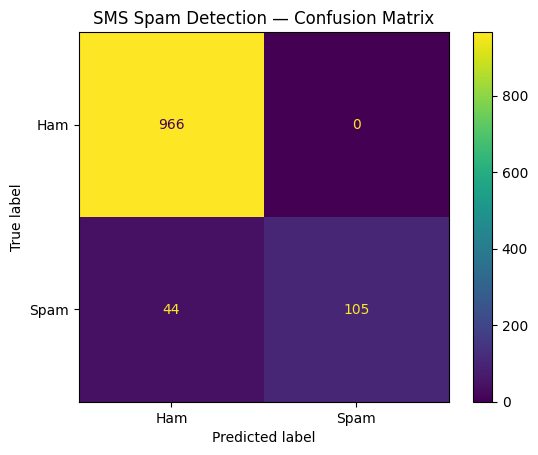

In [12]:
# Plot SMS confusion matrix

spam_cm = confusion_matrix(y_test_spam, spam_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=spam_cm,
    display_labels=["Ham", "Spam"]
)

disp.plot()
plt.title("SMS Spam Detection — Confusion Matrix")
plt.show()

## Error interpretation

For spam filtering, a **false positive** means a real ham message is classified as spam. This can be particularly inconvenient because an important legitimate message could be hidden or missed.

A **false negative** means a spam message reaches the inbox. That is undesirable because unwanted messages are not blocked.

If the application places a strong priority on protecting legitimate messages from being incorrectly blocked, **precision** becomes especially important because precision asks: “Of the messages predicted as spam, how many were actually spam?” If the main priority is catching as much spam as possible, **recall** becomes more important. The lab asks you to make this application-specific trade-off.

# Part 4 — Task A: Word Interpretation

Naive Bayes stores a probability for each feature given each class. We compare the spam and ham log-probabilities to find words more strongly associated with one class than the other.

In [4]:
# Find the 15 words most associated with spam and ham

feature_log_prob = spam_nb.feature_log_prob_
classes = spam_nb.classes_

# classes are [0, 1] where 0 = ham and 1 = spam
ham_log_prob = feature_log_prob[0]
spam_log_prob = feature_log_prob[1]

log_prob_difference = spam_log_prob - ham_log_prob

spam_indices = np.argsort(log_prob_difference)[-15:][::-1]
ham_indices = np.argsort(log_prob_difference)[:15]

spam_words = pd.DataFrame({
    "Word": spam_feature_names[spam_indices],
    "Spam_minus_Ham_Log_Probability": log_prob_difference[spam_indices]
})

ham_words = pd.DataFrame({
    "Word": spam_feature_names[ham_indices],
    "Spam_minus_Ham_Log_Probability": log_prob_difference[ham_indices]
})

print("15 words most strongly associated with SPAM:")
display(spam_words)

print("15 words most strongly associated with HAM:")
display(ham_words)

NameError: name 'spam_nb' is not defined

### Interpretation

The words above are not simply “the most common words.” They are words whose learned class probabilities differ strongly between spam and ham. After running the notebook, inspect whether the spam-associated words fit your expectations, such as promotional or prize-related language, and whether ham-associated words look more like ordinary personal communication.

The exact words should be taken from your model's output rather than assumed in advance.

In [5]:
# Test our own messages

custom_messages = [
    "Congratulations! You have won a free cash prize. Click now to claim your reward!",
    "Hi, I will meet you at the university after class.",
    "URGENT! You have been selected for a free bonus. Reply now to receive it."
]

custom_clean = (
    pd.Series(custom_messages)
    .str.lower()
    .str.replace(r"[^a-z0-9\s]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

custom_vec = spam_vectorizer.transform(custom_clean)
custom_pred = spam_nb.predict(custom_vec)

custom_result = pd.DataFrame({
    "Message": custom_messages,
    "Prediction": ["SPAM" if p == 1 else "HAM" for p in custom_pred]
})

display(custom_result)

NameError: name 'spam_vectorizer' is not defined

### Custom-message discussion

The predictions should generally match the obvious examples because the model has learned word patterns from the training SMS messages. If a prediction is unexpected, it may be because the exact wording was uncommon in the training data or because the model relies on individual word probabilities rather than complete sentence meaning.

# Part 5 — Task A: Kaggle Notebook Submission

The lab requires creating a Kaggle notebook attached to the SMS Spam Collection dataset, reproducing the Task A pipeline, running all cells, adding a short Markdown summary, and publishing with **Save & Run All (Public)**. The public URL should then be recorded in the final notebook.

**Kaggle Notebook URL:**  
/kaggle/input/datasets/nasirindhar/sms-spam-collection/spam.xls

# Part 6 — Task B: Text Cleaning & Vectorization — Sentiment

Tweets can contain `@mentions`, URLs, hashtags, and other social-media-specific text. We will remove URLs and mentions as likely noise while keeping ordinary words. We will also lowercase the tweets.

The same fit-on-training-only rule is used here.

In [15]:
# Clean tweet text

tweets_df["text_clean"] = (
    tweets_df["text"]
    .astype(str)
    .str.lower()
    .str.replace(r"http\S+|www\S+", " ", regex=True)   # remove links
    .str.replace(r"@\w+", " ", regex=True)              # remove @mentions
    .str.replace(r"[^a-z0-9#\s]", " ", regex=True)      # keep hashtag words
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Encode negative = 0 and positive = 1
tweets_df["target"] = tweets_df["airline_sentiment"].map({
    "negative": 0,
    "positive": 1
})

X_tweet = tweets_df["text_clean"]
y_tweet = tweets_df["target"]

X_train_tweet, X_test_tweet, y_train_tweet, y_test_tweet = train_test_split(
    X_tweet,
    y_tweet,
    test_size=0.20,
    random_state=42,
    stratify=y_tweet
)

print("Training tweets:", len(X_train_tweet))
print("Testing tweets:", len(X_test_tweet))

Training tweets: 9232
Testing tweets: 2309


In [16]:
# Vectorize tweets with TF-IDF

tweet_vectorizer = TfidfVectorizer(
    lowercase=False,
    max_features=None
)

X_train_tweet_vec = tweet_vectorizer.fit_transform(X_train_tweet)
X_test_tweet_vec = tweet_vectorizer.transform(X_test_tweet)

tweet_feature_names = tweet_vectorizer.get_feature_names_out()

print("Training feature matrix shape:", X_train_tweet_vec.shape)
print("Testing feature matrix shape:", X_test_tweet_vec.shape)
print("Tweet vocabulary size:", len(tweet_feature_names))

Training feature matrix shape: (9232, 10075)
Testing feature matrix shape: (2309, 10075)
Tweet vocabulary size: 10075


### Cleaning justification

URLs and user mentions can occur frequently in tweets without directly expressing sentiment, so removing them can reduce noisy vocabulary. Lowercasing also prevents the same word in different capitalization forms from becoming separate features. This is a slightly stronger cleaning step than the SMS task because tweets contain social-media-specific elements.

# Part 7 — Task B: Naive Bayes Model & Evaluation

We now train Multinomial Naive Bayes on the tweet features and calculate the same four evaluation metrics plus a confusion matrix.

In [17]:
# Train Naive Bayes on sentiment data

tweet_nb = MultinomialNB()
tweet_nb.fit(X_train_tweet_vec, y_train_tweet)

tweet_pred = tweet_nb.predict(X_test_tweet_vec)

tweet_accuracy = accuracy_score(y_test_tweet, tweet_pred)
tweet_precision = precision_score(y_test_tweet, tweet_pred, zero_division=0)
tweet_recall = recall_score(y_test_tweet, tweet_pred, zero_division=0)
tweet_f1 = f1_score(y_test_tweet, tweet_pred, zero_division=0)

tweet_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [tweet_accuracy, tweet_precision, tweet_recall, tweet_f1]
})

display(tweet_results)

,Metric,Score
0,Accuracy,0.831096
1,Precision,1.000000
2,Recall,0.175476
3,F1-score,0.298561


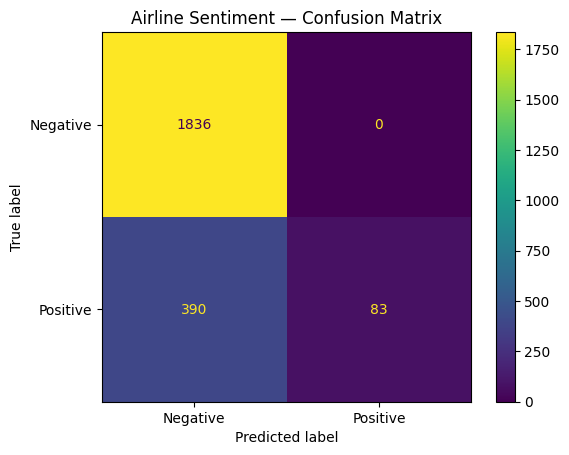

In [18]:
# Plot tweet confusion matrix

tweet_cm = confusion_matrix(y_test_tweet, tweet_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=tweet_cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()
plt.title("Airline Sentiment — Confusion Matrix")
plt.show()

In [19]:
# Compare Task A and Task B

comparison_nb = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Task A - Spam": [
        spam_accuracy,
        spam_precision,
        spam_recall,
        spam_f1
    ],
    "Task B - Sentiment": [
        tweet_accuracy,
        tweet_precision,
        tweet_recall,
        tweet_f1
    ]
})

display(comparison_nb)

,Metric,Task A - Spam,Task B - Sentiment
0,Accuracy,0.960538,0.831096
1,Precision,1.000000,1.000000
2,Recall,0.704698,0.175476
3,F1-score,0.826772,0.298561


### Comparison discussion

Use the actual values in the table above to describe which task produced higher or lower metrics. A useful explanation is that SMS spam can contain relatively formulaic patterns, while tweets often depend more on context, negation, sarcasm, and combinations of words.

The Naive Bayes model assumes that features are conditionally independent given the class. That assumption can be less realistic when the meaning of a tweet depends strongly on word combinations or context, such as “not good.” Therefore, the difference between the two tasks can be discussed in terms of how well the independence assumption fits each type of text, rather than only comparing the numerical scores.

# Part 8 — Task B: Kaggle Notebook Submission

Create a Kaggle notebook attached to the Twitter US Airline Sentiment dataset. Recreate the Task B cleaning, vectorization, Naive Bayes, evaluation, and confusion-matrix cells. Run everything from top to bottom, add a short Markdown summary, and publish it.

**Kaggle Notebook URL:**  
`PASTE_YOUR_TWITTER_KAGGLE_NOTEBOOK_URL_HERE`

# Part 9 — Cross-Task Comparison & Logistic Regression

The lab asks for a Task A vs Task B Naive Bayes comparison and then a Logistic Regression comparison using the **same Task A vectorized features**.

In [20]:
# Final Naive Bayes comparison table

nb_comparison_table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Task A - SMS Spam": [
        spam_accuracy, spam_precision, spam_recall, spam_f1
    ],
    "Task B - Twitter Sentiment": [
        tweet_accuracy, tweet_precision, tweet_recall, tweet_f1
    ]
})

display(nb_comparison_table)

,Metric,Task A - SMS Spam,Task B - Twitter Sentiment
0,Accuracy,0.960538,0.831096
1,Precision,1.000000,1.000000
2,Recall,0.704698,0.175476
3,F1-score,0.826772,0.298561


In [21]:
# Logistic Regression on the SAME Task A features

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_spam_vec, y_train_spam)

log_pred = log_reg.predict(X_test_spam_vec)

log_accuracy = accuracy_score(y_test_spam, log_pred)
log_precision = precision_score(y_test_spam, log_pred, zero_division=0)
log_recall = recall_score(y_test_spam, log_pred, zero_division=0)
log_f1 = f1_score(y_test_spam, log_pred, zero_division=0)

logistic_vs_nb = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Naive Bayes": [
        spam_accuracy,
        spam_precision,
        spam_recall,
        spam_f1
    ],
    "Logistic Regression": [
        log_accuracy,
        log_precision,
        log_recall,
        log_f1
    ]
})

display(logistic_vs_nb)

,Metric,Naive Bayes,Logistic Regression
0,Accuracy,0.960538,0.972197
1,Precision,1.000000,0.991667
2,Recall,0.704698,0.798658
3,F1-score,0.826772,0.884758


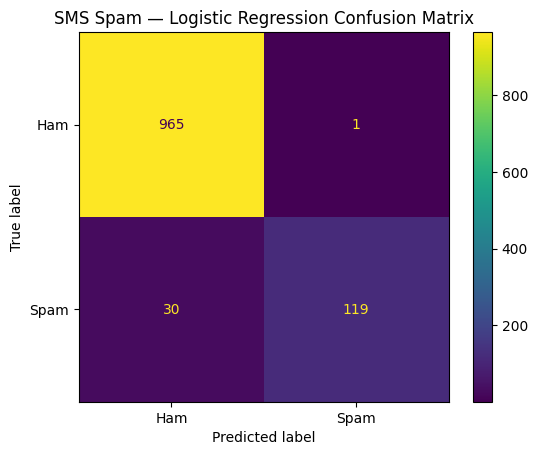

In [22]:
# Confusion matrix for Logistic Regression

log_cm = confusion_matrix(y_test_spam, log_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=log_cm,
    display_labels=["Ham", "Spam"]
)

disp.plot()
plt.title("SMS Spam — Logistic Regression Confusion Matrix")
plt.show()

### Logistic Regression discussion

Compare the two columns in the table above for accuracy, precision, recall, and F1-score. The model with the higher value for a particular metric performed better on that particular metric; avoid treating one metric as universally best because the application determines which error matters more.

Using the same vectorized features makes the comparison fairer because the main change is the classifier rather than the feature representation. Differences can also be discussed in relation to Naive Bayes' conditional-independence assumption and Logistic Regression's ability to learn weighted relationships among the features.

# Part 10 — Final Reflection & Conclusion

The following conclusion is written as a template that should be finalized after running the notebook and replacing the bracketed result statements with your actual output.

## Conclusion

This lab showed how Naive Bayes can be applied to two different text-classification problems: SMS spam detection and airline tweet sentiment analysis. The text was converted into numerical TF-IDF features because machine-learning classifiers require numerical input rather than raw sentences. Multinomial Naive Bayes was then trained and evaluated using accuracy, precision, recall, F1-score, and confusion matrices. The most predictive words in the spam model were obtained directly from the learned class log-probabilities, which provided an interpretable view of what the model learned. **After running the notebook, insert your actual observation here about which task achieved higher metrics and why.** Logistic Regression was also trained on the same SMS features so that the classifier comparison used the same representation. **Insert your actual numerical comparison here rather than guessing the winner before running the code.** One important limitation of Naive Bayes is its conditional-independence assumption, which can be unrealistic when meaning depends on combinations of words, negation, sarcasm, or broader context. Overall, the lab demonstrated how the same machine-learning workflow can transfer from structured tabular data to unstructured text data.

## Task 20 — Published Kaggle Notebook URLs

### Task A — SMS Spam Collection
`PASTE_YOUR_SMS_KAGGLE_NOTEBOOK_URL_HERE`

### Task B — Twitter US Airline Sentiment
`PASTE_YOUR_TWITTER_KAGGLE_NOTEBOOK_URL_HERE`

# Quick Viva Preparation

**1. What is Naive Bayes?**  
Naive Bayes is a probabilistic classification algorithm based on Bayes' theorem. It assumes features are conditionally independent given the class.

**2. Why is MultinomialNB used for text?**  
It works well with features representing word counts or TF-IDF values.

**3. What is TF-IDF?**  
TF-IDF gives a numerical weight to words based on their importance in a document relative to the collection of documents.

**4. Why fit the vectorizer only on training data?**  
To prevent information from the test set from leaking into training.

**5. What is a false positive in spam detection?**  
A normal ham message incorrectly classified as spam.

**6. What is a false negative in spam detection?**  
A spam message incorrectly classified as ham.

**7. What is precision?**  
Of all items predicted positive, precision tells us how many were actually positive.

**8. What is recall?**  
Of all actual positive items, recall tells us how many the model correctly found.

**9. What is F1-score?**  
F1 is the harmonic mean of precision and recall.

**10. Why remove neutral tweets?**  
The lab defines sentiment classification as positive versus negative, so neutral rows are removed to create the required binary problem.

**11. What is a confusion matrix?**  
It shows correct and incorrect predictions for each class.

**12. Why can tweets be harder than spam messages?**  
Tweets can depend more on context, negation, sarcasm, and combinations of words.

**13. What does MultinomialNB learn?**  
It learns class-specific probabilities for the features and uses them to predict the class of new text.

**14. Why compare Logistic Regression on the same features?**  
Using the same features makes the classifier comparison more meaningful.

**15. What is the main limitation of the naive assumption?**  
Words are not truly independent in natural language; their meaning can depend on nearby words and context.